In [1]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score

In [2]:
# Load training and testing datasets

eval_X_train = np.load(
    "../dataset/processed/X_train_scaled.npy"
)

eval_X_test = np.load(
    "../dataset/processed/X_test_scaled.npy"
)

eval_y_train = np.load(
    "../dataset/processed/y_train.npy"
)

eval_y_test = np.load(
    "../dataset/processed/y_test.npy"
)

print("Training features:", eval_X_train.shape)
print("Testing features:", eval_X_test.shape)

print("Training labels:", eval_y_train.shape)
print("Testing labels:", eval_y_test.shape)

Training features: (51500, 63)
Testing features: (12876, 63)
Training labels: (51500,)
Testing labels: (12876,)


In [3]:
# Define machine learning models

accuracy_models = {

    "KNN": KNeighborsClassifier(
        n_neighbors=3
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ),

    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Successfully defined models:")

for model_name in accuracy_models:
    print(model_name)

Successfully defined models:
KNN
SVM
Decision Tree
Random Forest


In [5]:
accuracy_results = []

for model_name, model_instance in accuracy_models.items():

    print("\n" + "=" * 50)
    print(f"Evaluating: {model_name}")
    print("=" * 50)

    # Training
    start_time = time.time()

    model_instance.fit(
        eval_X_train,
        eval_y_train
    )

    training_duration = time.time() - start_time

    # Training predictions
    eval_train_predictions = model_instance.predict(
        eval_X_train
    )

    # Testing predictions
    eval_test_predictions = model_instance.predict(
        eval_X_test
    )

    # Calculate training accuracy
    training_accuracy = accuracy_score(
        eval_y_train,
        eval_train_predictions
    ) * 100

    # Calculate testing accuracy
    testing_accuracy = accuracy_score(
        eval_y_test,
        eval_test_predictions
    ) * 100

    # Calculate accuracy gap
    accuracy_gap = training_accuracy - testing_accuracy

    # Store results
    accuracy_results.append({

        "Model": model_name,

        "Training Accuracy (%)": training_accuracy,

        "Testing Accuracy (%)": testing_accuracy,

        "Accuracy Gap (%)": accuracy_gap,

        "Training Time (s)": training_duration
    })

    print(f"Training Accuracy: {training_accuracy:.4f}%")
    print(f"Testing Accuracy: {testing_accuracy:.4f}%")
    print(f"Accuracy Gap: {accuracy_gap:.4f}%")
    print(f"Training Time: {training_duration:.4f} seconds")


Evaluating: KNN
Training Accuracy: 99.9126%
Testing Accuracy: 99.8524%
Accuracy Gap: 0.0602%
Training Time: 0.0307 seconds

Evaluating: SVM
Training Accuracy: 99.9146%
Testing Accuracy: 99.8447%
Accuracy Gap: 0.0699%
Training Time: 5.8252 seconds

Evaluating: Decision Tree
Training Accuracy: 100.0000%
Testing Accuracy: 99.0758%
Accuracy Gap: 0.9242%
Training Time: 5.3032 seconds

Evaluating: Random Forest
Training Accuracy: 100.0000%
Testing Accuracy: 99.8680%
Accuracy Gap: 0.1320%
Training Time: 3.2696 seconds


In [6]:
accuracy_results_df = pd.DataFrame(accuracy_results)

accuracy_results_df = accuracy_results_df.sort_values(
    by="Testing Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(accuracy_results_df.round(4))

,Model,Training Accuracy (%),Testing Accuracy (%),Accuracy Gap (%),Training Time (s)
0,Random Forest,100.0000,99.8680,0.1320,3.2696
1,KNN,99.9126,99.8524,0.0602,0.0307
2,SVM,99.9146,99.8447,0.0699,5.8252
3,Decision Tree,100.0000,99.0758,0.9242,5.3032


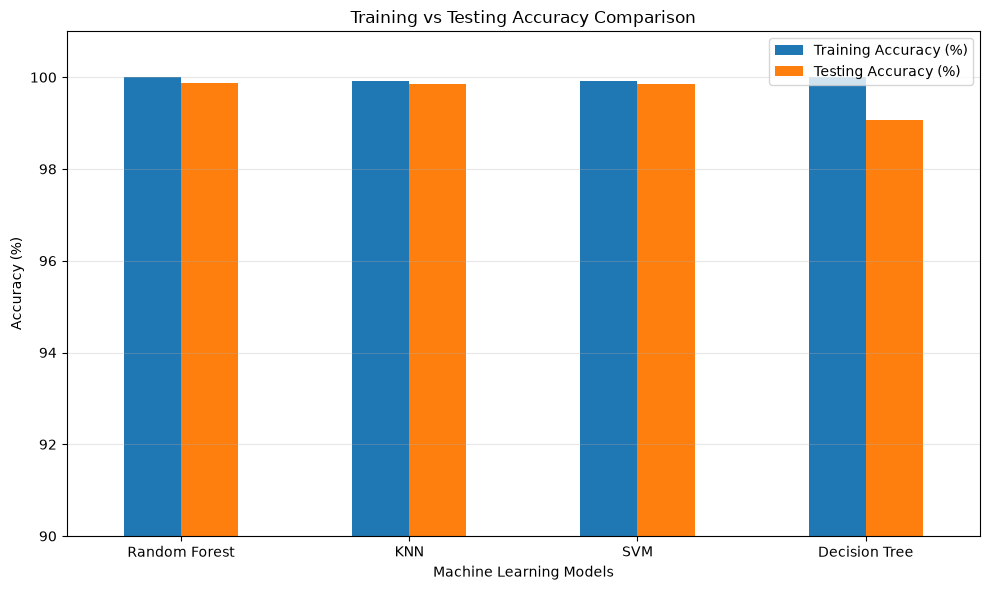

In [7]:
accuracy_plot = accuracy_results_df.set_index("Model")

accuracy_plot[
    [
        "Training Accuracy (%)",
        "Testing Accuracy (%)"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Training vs Testing Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(90, 101)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

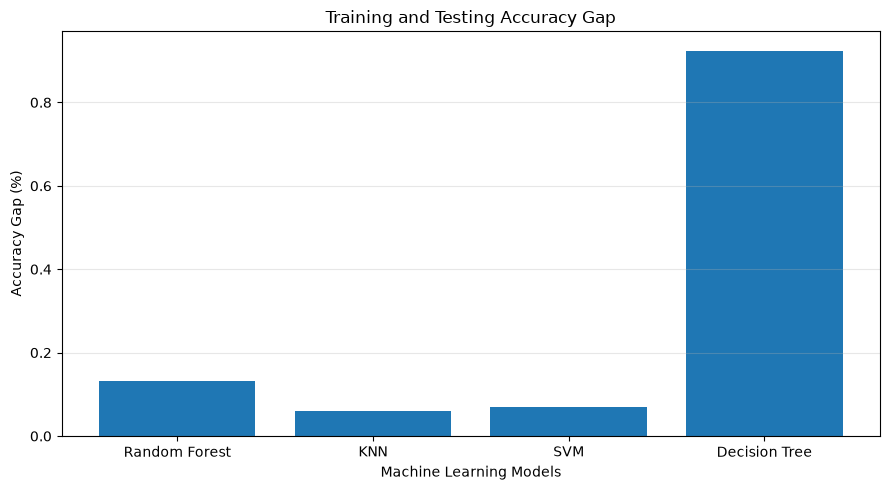

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    accuracy_results_df["Model"],
    accuracy_results_df["Accuracy Gap (%)"]
)

plt.title("Training and Testing Accuracy Gap")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy Gap (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
accuracy_results_df.to_csv(
    "../results/model_accuracy_comparison.csv",
    index=False
)

print("Accuracy comparison saved successfully!")

Accuracy comparison saved successfully!


In [11]:
git add notebooks/Test the acuarccay of tetinig and traing set.ipynb

SyntaxError: invalid syntax (698981355.py, line 1)

In [12]:
git status


SyntaxError: invalid syntax (339777499.py, line 1)